In [1]:
import random
from pathlib import Path

import sqlite3

from IPython.display import Markdown, display

import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_predict, KFold, GroupKFold
import numpy as np
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
from scipy import stats
import statsmodels.api as sm
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data" / "fifa-2026"
DB_PATH = PROJECT_ROOT / "db" / "fifa2026.db"
DB_PATH.parent.mkdir(exist_ok=True)

PERMA_SEED = 42
random.seed(PERMA_SEED)
np.random.seed(PERMA_SEED)

BLUE, RED = "#4C72B0", "#C44E52"  

In [2]:
def q(sql, params=None):
    with sqlite3.connect(DB_PATH) as c:
        return pd.read_sql_query(sql, c, params=params)


def rmse(y_true, y_pred):
    return mean_squared_error(y_true, y_pred) ** 0.5


def show(markdown_text):
    display(Markdown(markdown_text))

In [3]:
final_dataset = q("""
WITH
squad_totals AS (
    SELECT
        team_id,
        AVG((julianday('2026-06-11') - julianday(date_of_birth)) / 365.25) AS squad_age,
        SUM(caps) AS total_caps,
        SUM(goals) AS goals_sum
    FROM squads_and_players
    GROUP BY team_id
),
match_multiplier AS (
    SELECT 
        match_id,
        date, 
        home_team_id AS team_id,
        home_score AS goals_for, 
        away_score AS goals_against
    FROM matches
    UNION ALL
    SELECT 
        match_id, 
        date, 
        away_team_id,
        away_score,
        home_score
    FROM matches
),
team_timeline AS (
    SELECT
        match_id,
        team_id,
        julianday(date) - julianday(LAG(date) OVER w) AS rest_days,
        AVG(goals_for - goals_against) OVER (
            PARTITION BY team_id
            ORDER BY date, match_id
            ROWS BETWEEN 3 PRECEDING AND 1 PRECEDING
        ) AS recent_form
    FROM match_multiplier
    WINDOW w AS (PARTITION BY team_id ORDER BY date, match_id)
)
SELECT
    matches.match_id,
    matches.home_team_id,
    matches.away_team_id,
    t1.elo_rating - t2.elo_rating AS elo_rating_difference,
    home.squad_age - away.squad_age AS squad_age_difference,
    home.total_caps - away.total_caps AS caps_difference,
    home.goals_sum - away.goals_sum AS goal_total_difference,
    COALESCE(tl_home.rest_days, 10) - COALESCE(tl_away.rest_days, 10) AS rest_days_difference,
    stages.is_knockout AS is_knockout,
    (t1.fifa_code = venues.country) - (t2.fifa_code = venues.country) AS host_advantage,
    COALESCE(tl_home.recent_form, 0) - COALESCE(tl_away.recent_form, 0) AS form_difference,
    matches.home_score - matches.away_score AS goal_difference
FROM matches
JOIN teams AS t1 ON t1.team_id = matches.home_team_id
JOIN teams AS t2 ON t2.team_id = matches.away_team_id
JOIN venues ON venues.venue_id = matches.venue_id
JOIN tournament_stages AS stages ON stages.stage_id = matches.stage_id
JOIN squad_totals AS home ON home.team_id = matches.home_team_id
JOIN squad_totals AS away ON away.team_id = matches.away_team_id
JOIN team_timeline AS tl_home ON tl_home.match_id = matches.match_id AND tl_home.team_id = matches.home_team_id
JOIN team_timeline AS tl_away ON tl_away.match_id = matches.match_id AND tl_away.team_id = matches.away_team_id
ORDER BY matches.match_id;
""")

In [4]:
>>> final_dataset.head()

,match_id,home_team_id,away_team_id,elo_rating_difference,squad_age_difference,caps_difference,goal_total_difference,rest_days_difference,is_knockout,host_advantage,form_difference,goal_difference
0,1,1,2,190,1.092297,699,54,0.0,0,1,0.0,2
1,2,3,4,60,0.444901,236,45,0.0,0,0,0.0,1
2,3,5,6,150,0.516190,360,40,0.0,0,1,0.0,0
3,4,13,14,125,-2.097615,272,74,0.0,0,1,0.0,3
4,5,7,8,-260,1.200653,438,91,0.0,0,0,0.0,0


In [5]:
>>> final_dataset.shape

(104, 12)

In [6]:
ID_COLS = ["match_id", "home_team_id", "away_team_id"]
TARGET = "goal_difference"

FEATURES = [clmn for clmn in final_dataset.columns if clmn not in ID_COLS + [TARGET]]

In [7]:
>>> FEATURES

['elo_rating_difference',
 'squad_age_difference',
 'caps_difference',
 'goal_total_difference',
 'rest_days_difference',
 'is_knockout',
 'host_advantage',
 'form_difference']

In [8]:
# works great! linear reg now

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    final_dataset[FEATURES], final_dataset[TARGET], test_size=0.2, random_state=PERMA_SEED
)

In [10]:
>>> X_train

,elo_rating_difference,squad_age_difference,caps_difference,goal_total_difference,rest_days_difference,is_knockout,host_advantage,form_difference
55,-65,1.643132,-46,-21,0.0,0,0,-1.000000
22,10,-3.451377,-971,-58,0.0,0,0,0.000000
76,-25,-0.955194,-95,-41,0.0,1,0,0.333333
44,360,-0.177960,204,140,0.0,0,0,2.000000
72,-175,-0.164271,-435,-68,0.0,1,0,-2.000000
...,...,...,...,...,...,...,...,...
71,250,1.353551,591,86,0.0,0,0,-1.000000
14,-300,-0.226189,0,22,0.0,0,0,0.000000
92,-110,1.287843,418,143,0.0,1,0,-0.666667
51,45,-3.051229,-973,-122,0.0,0,0,1.500000


In [11]:
model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)

In [12]:
r2 = r2_score(y_test, pred)
rmse_v = mean_squared_error(y_test, pred) ** 0.5
print(f"Test R^2:  {r2:.3f}")
print(f"Test RMSE: {rmse_v:.3f} goals")

pd.Series(model.coef_, index=FEATURES, name="coefficient").sort_values()

X_sm = sm.add_constant(X_train)
ols_fds = sm.OLS(y_train, X_sm).fit()
>>>ols_fds.summary()

Test R^2:  0.386
Test RMSE: 1.763 goals


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        goal_difference   R-squared:                       0.519
Model:                            OLS   Adj. R-squared:                  0.467
Method:                 Least Squares   F-statistic:                     9.981
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           2.58e-09
Time:                        15:01:08   Log-Likelihood:                -142.65
No. Observations:                  83   AIC:                             303.3
Df Residuals:                      74   BIC:                             325.1
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
=========================================================================================
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                     0.2444      0.192      1.273      0.207      -0.138       0.627
elo_rating_difference     0.0064      0.001      6.889      0.000       0.005       0.008
squad_age_difference      0.0846      0.160      0.529      0.599      -0.234       0.403
caps_difference          -0.0013      0.001     -1.269      0.209      -0.003       0.001
goal_total_difference     0.0011      0.004      0.264      0.792      -0.007       0.009
rest_days_difference      0.1795      0.308      0.584      0.561      -0.433       0.792
is_knockout              -0.7783      0.388     -2.006      0.048      -1.551      -0.005
host_advantage            1.1681      0.581      2.012      0.048       0.011       2.325
form_difference          -0.0202      0.103     -0.197      0.845      -0.224       0.184
==============================================================================
Omnibus:                        0.126   Durbin-Watson:                   1.671
Prob(Omnibus):                  0.939   Jarque-Bera (JB):                0.286
Skew:                           0.067   Prob(JB):                        0.867
Kurtosis:                       2.745   Cond. No.                     1.24e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.24e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

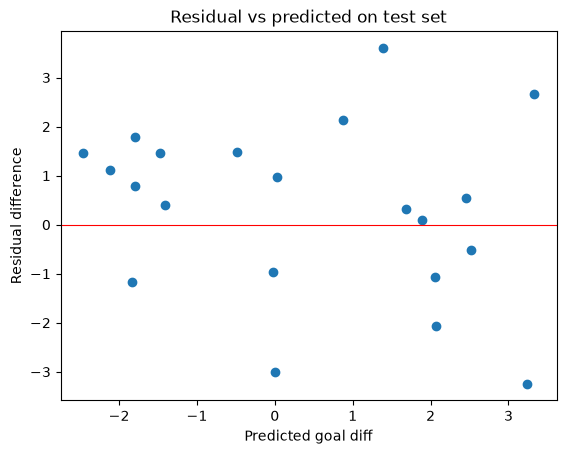

In [13]:
fig, axs = plt.subplots()

axs.scatter(pred, y_test - pred)
axs.axhline(0, color="red", linewidth=0.8)
axs.set_xlabel("Predicted goal diff")
axs.set_ylabel("Residual difference")
axs.set_title("Residual vs predicted on test set")
plt.show()

# So what did we actually do here?

We asked two simple questions.

1. Can we predict by how many goals does a team beat the other team?
2. Can we predict how many goals a team scores in a match?

What did we find?

1. We can predict.. but only sort of. Both models beat the average random guess. Our predictions of the win margin are off by 1.6 goals on average, where a no-skill average guess is off by 2 goals.  Our predictions of scored goals are off by 1.3 goals, against 1.4 for an average guess.
2. The Elo rating for team which explains the strength of the team pre-tournament did almost all of the heavy lifting. Higher rated team will probably score more and win.
3. Playing in your own country helps (as we assumed, the audience is usually considered the 12th person in the field) - but only applicable to US, Canada, and Mexico. Knockout matches were tight.
4. Football is hard to predict, and most of the factors affecting the score that day are all the factors not in the spreadsheet.
5. Backing the higher-rated team picks winner in about 7 out of 8 matches that had no tie and had a winner. Not a flaw, but that's how football is (we suppose).

## For this problem:

Understanding the factors we used:

| SN | Column name | What it does | Why does this matter | Known before kickoff?
| -- | -- | -- | -- | -- |
| 1 | Elo rating difference | Team A strength - Team B Strength, higher = stronger, before tourney ratings | Stronger team win often, and with more goals | Yes, pre-tourney ratings |
| 2 | Squad age difference | How older is Team A's squad compared to Team B on average? | Experience vs energy - do older squads perform better, or do younger blood prevail? | Yes - DOB to kickoff day math | 
| 3 | Caps difference | Team A's international appearance vs Team B's (difference) | Do big-match experience matter here? | Yes, pre-WC caps count |
| 4 | Goal difference | Total international career goals by the entire squad, combined (Team A - Team B) | How good is the attack for each team? | Yes, from squad pre-WC |
| 5 | Rest days difference | Days since each team played the last game (Team A - Team B, the usual). First match is counted as 10 days of difference | Tired players probably don't perform as well | Yes, schedule is published before world cup |
| 6 | Is knockout? | 1 if knockout, 0 if not | Higher stakes - do teams perform better under pressure? | Yes, known in advance.|
| 7 | Host advantage | +1 if team A in home country, -1 if team B, 0 if neither | home crowd, 12th man | Yes, venue and teams are known in advance |
| 8 | Form difference | Recent form: last 3 matches average goal margin, team A - team B | Winning and goal streak carries over momentum, brings wins | Yes, only earlier matches |

## What did we leave out here?

1. FIFA ranking: almost similar to Elo rating. Redundancy.
2. Squad market value: the dataset states the value for non-star players were estimated based on team rankings - so not real data per se
3. Player height: We don't see the Dutch winning every world cup, seems sensible to not use average player height to win the match.

## Basic EDA

In [14]:
y = final_dataset[TARGET]
avg_goals = q("SELECT AVG(home_score + away_score) AS g FROM matches")["g"][0]
n_t1, n_draw, n_t2 = int((y > 0).sum()), int((y == 0).sum()), int((y < 0).sum())
big = y.abs().max()
pens = q("SELECT COUNT(*) AS n FROM matches WHERE result_type = 'Penalties'")["n"][0]
mode_m = int(y.value_counts().idxmax())
mode_txt = "a draw" if mode_m == 0 else f"a {abs(mode_m)}-goal win for Team {1 if mode_m > 0 else 2}"

print(f'Average goals: {avg_goals}')
print(f'{n_t1} matches were won by Team 1, {n_draw} ended in a draw and {n_t2} were won by Team 2 and of the level ones, {pens} were settled on penalties)')
print(f'Biggest win margin: {big} goals')

Average goals: 2.9615384615384617
50 matches were won by Team 1, 24 ended in a draw and 30 were won by Team 2 and of the level ones, 3 were settled on penalties)
Biggest win margin: 6 goals


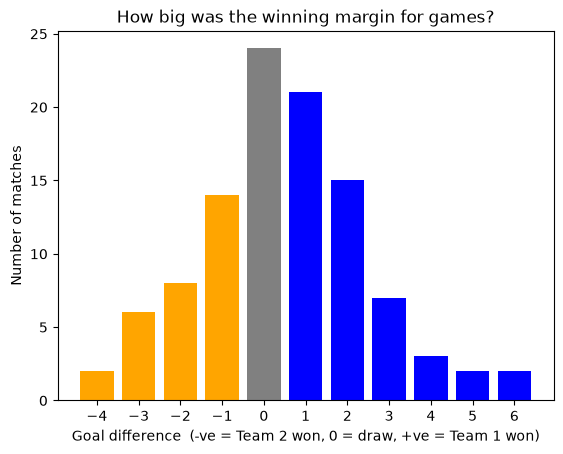

In [15]:
margin_counts = y.value_counts().sort_index()
fig, ax = plt.subplots()
colors = ["orange" if m < 0 else "grey" if m == 0 else "blue" for m in margin_counts.index]
ax.bar(margin_counts.index, margin_counts.values, color=colors)
ax.set_xlabel("Goal difference  (-ve = Team 2 won, 0 = draw, +ve = Team 1 won)")
ax.set_ylabel("Number of matches")
ax.set_title("How big was the winning margin for games?")
ax.set_xticks(margin_counts.index)
plt.show()

## Average goal difference - Elo difference (mapped)

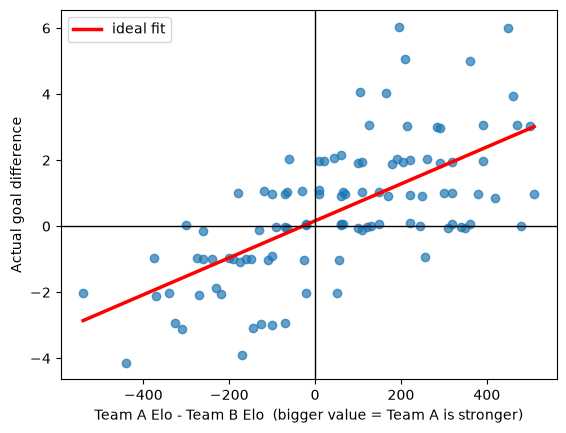

In [16]:
x = final_dataset["elo_rating_difference"]
slope, intercept = np.polyfit(x, y, 1)
r_elo = x.corr(y)

fig, axs = plt.subplots()
rng = np.random.default_rng(PERMA_SEED)
axs.scatter(x, y + rng.normal(0, 0.08, len(y)), alpha=0.7)
xs = np.linspace(x.min(), x.max(), 50)
axs.plot(xs, intercept + slope * xs, color="red", lw=2.5, label="ideal fit")
axs.axhline(0, color="black", lw=1)
axs.axvline(0, color="black", lw=1)
axs.set_xlabel("Team A Elo - Team B Elo  (bigger value = Team A is stronger)")
axs.set_ylabel("Actual goal difference")
axs.legend()
plt.show()

In [17]:
display(f'Correlation value is: {r_elo:+.2f}. Every 100 elo point adds {(slope * 100):+.2f} more goals of margin')

'Correlation value is: +0.65. Every 100 elo point adds +0.56 more goals of margin'

## Performance analysis

Based on the model's run, with simple 80-20 split for train/test, the values that we come across is,

In [18]:
print(f'Across {len(y_test)} test matches, the typical error was {rmse_v:.2f} goals and it explains {r2*100:.2f}% differences between them')

Across 21 test matches, the typical error was 1.76 goals and it explains 38.58% differences between them


## Cross-validation

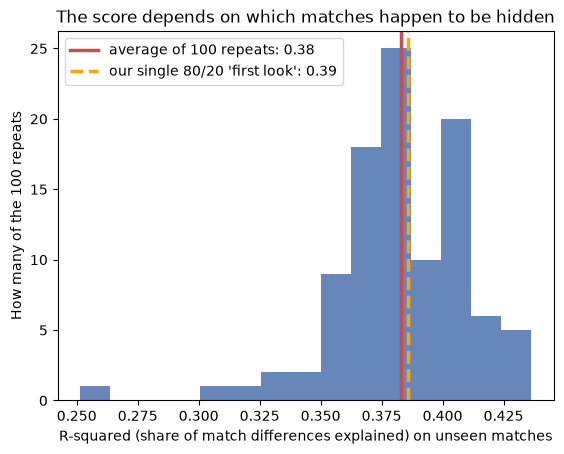

In [19]:
MODEL = make_pipeline(StandardScaler(), LinearRegression())

def oof_predict(model, X, y, seed, groups=None):
    """Out-of-fold predictions - every row is predicted by a model that never saw that row."""
    if groups is None:
        cv = KFold(n_splits=5, shuffle=True, random_state=seed)
    else:
        cv = GroupKFold(n_splits=5, shuffle=True, random_state=seed)
    return cross_val_predict(model, X, y, cv=cv, groups=groups)

def repeated_cv(X, y, groups=None, n_repeats=100):
    """Repeating the 5-fold test many times with different shuffles and returning scores and predictions."""
    rows, preds = [], []
    for seed in range(n_repeats):
        p = oof_predict(MODEL, X, y, seed, groups)
        b = oof_predict(DummyRegressor(), X, y, seed, groups) # dummy prediction, bottom of the barrel average
        rows.append({
            "r2": r2_score(y, p), "rmse": rmse(y, p), "base_rmse": rmse(y, b),
            "base_r2": r2_score(y, b),
            "within1": (np.abs(p - y) <= 1).mean(), "base_within1": (np.abs(b - y) <= 1).mean(),
        })
        preds.append(p)
    return pd.DataFrame(rows), np.array(preds)


cv, P = repeated_cv(final_dataset[FEATURES].astype(float), final_dataset[TARGET])

fig, axs = plt.subplots()
axs.hist(cv["r2"], bins=15, color=BLUE, alpha=0.85)
axs.axvline(cv["r2"].mean(), color=RED, lw=2.5, label=f"average of 100 repeats: {cv['r2'].mean():.2f}")
axs.axvline(r2, color="orange", lw=2.5, ls="--", label=f"our single 80/20 'first look': {r2:.2f}")
axs.set_xlabel("R-squared (share of match differences explained) on unseen matches")
axs.set_ylabel("How many of the 100 repeats")
axs.set_title("The score depends on which matches happen to be hidden")
axs.legend()
plt.show()

In [20]:
improvement = 1 - cv["rmse"].mean() / cv["base_rmse"].mean()

In [21]:
show(f"""What the numbers say (average over 100 repeats)

| | Our model | Dummy Regressor |
|---|---|---|
| Typical error | {cv['rmse'].mean():.2f} goals | {cv['base_rmse'].mean():.2f} goals |
| R^2 | {cv['r2'].mean():.2f} (range {cv['r2'].min():.2f} to {cv['r2'].max():.2f}) | {cv['base_r2'].mean():.2f} |

- The model's predictions are {improvement:.0%} closer to the truth than a random guess using a DummyRegressor. It beats the no-skill guess in {int((cv['rmse'] < cv['base_rmse']).sum())} of 100 repeats.
- The R^2 score goes from {cv['r2'].min():.2f} to {cv['r2'].max():.2f} depending on the shuffle, so one 80/20 split, which gave {r2:.2f}, is not a reliable verdict.
  The model explains about {cv['r2'].mean():.0%} of the differences between matches, and the other {1 - cv['r2'].mean():.0%} comes from chance and from information outside the eight inputs.""")

What the numbers say (average over 100 repeats)

| | Our model | Dummy Regressor |
|---|---|---|
| Typical error | 1.58 goals | 2.04 goals |
| R^2 | 0.38 (range 0.25 to 0.44) | -0.02 |

- The model's predictions are 22% closer to the truth than a random guess using a DummyRegressor. It beats the no-skill guess in 100 of 100 repeats.
- The R^2 score goes from 0.25 to 0.44 depending on the shuffle, so one 80/20 split, which gave 0.39, is not a reliable verdict.
  The model explains about 38% of the differences between matches, and the other 62% comes from chance and from information outside the eight inputs.

## Prediction vs Reality

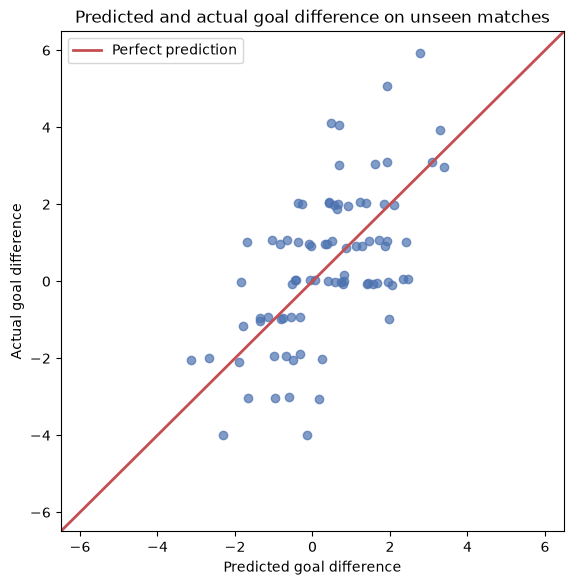

In [22]:
oof21 = oof_predict(MODEL, X_train, y_train, PERMA_SEED)
fig, axs = plt.subplots(figsize=(6.5, 6.5))
rng = np.random.default_rng(PERMA_SEED)
axs.scatter(oof21, y_train + rng.normal(0, 0.08, len(y_train)), alpha=0.7, color=BLUE)
lim = max(abs(y_train).max(), abs(oof21).max()) + 0.5
axs.plot([-lim, lim], [-lim, lim], color=RED, lw=2, label="Perfect prediction")
axs.set_xlim(-lim, lim)
axs.set_ylim(-lim, lim)
axs.set_xlabel("Predicted goal difference")
axs.set_ylabel("Actual goal difference")
axs.set_title("Predicted and actual goal difference on unseen matches")
axs.legend()
plt.show()

## Summary for the problem

We predicted the goal difference of all 104 matches from eight inputs known before kick-off. On test set matches the model is off by about 1.6 goals, against 2.0 for a dummy guess, and it explains about 4 in 10 of the differences between matches. The Elo rating has by far the largest effect. Playing at home raises the goal difference and knockout matches lower it. The other inputs show no convincing effect, and international caps shows a borderline negative effect that we do not trust. A model that uses only the Elo rating predicts about as well, so the other inputs add little.

In [23]:
# DONE!

# SECOND QUESTION

In [24]:
goals_pred_ds = q("""
WITH
squad_totals AS (
    SELECT
        team_id,
        SUM(position = 'FWD') AS forwards
        FROM squads_and_players
        GROUP BY team_id
),
team_match AS (
    SELECT match_id,
           date,
           home_team_id AS team_id,
           away_team_id AS opponent_id,
           home_score AS goals_scored,
           away_score AS goals_conceded,
           latitude AS lat,
           longitude AS lon
    FROM matches
    JOIN venues ON venues.venue_id = matches.venue_id
    UNION ALL
    SELECT
        match_id,
        date,
        away_team_id,
        home_team_id,
        away_score,
        home_score,
        latitude,
        longitude
    FROM matches
    JOIN venues ON venues.venue_id = matches.venue_id
),
team_timeline AS (
    SELECT
        match_id,
        team_id,
        opponent_id,
        goals_scored,
        lat,
        lon,
        LAG (lat) OVER w AS prev_lat,
        LAG (lon) OVER w AS prev_lon
    FROM team_match
    WINDOW w AS (PARTITION BY team_id ORDER BY date, match_id)
)
SELECT
    tl.match_id,
    tl.team_id,
    tl.opponent_id,
    t.elo_rating AS team_elo,
    o.elo_rating AS opponent_elo,
    venues.elevation_meters AS venue_elevation_m,
    sq.forwards AS team_forwards,
    CASE WHEN tl.prev_lat IS NULL THEN 0
         ELSE 2 * 6371 * asin(sqrt(
              power(sin(radians(tl.lat - tl.prev_lat) / 2), 2)
              + cos(radians(tl.prev_lat)) * cos(radians(tl.lat))
              * power(sin(radians(tl.lon - tl.prev_lon) / 2), 2)))
    END AS travel_km,
    stages.is_knockout AS is_knockout,
    (t.fifa_code = venues.country) AS team_is_host,
    venues.capacity AS venue_capacity,
    tl.goals_scored AS goals_scored
FROM team_timeline AS tl
JOIN matches AS m ON m.match_id = tl.match_id
JOIN teams AS t ON t.team_id = tl.team_id
JOIN teams AS o ON o.team_id = tl.opponent_id
JOIN venues ON venues.venue_id = m.venue_id
JOIN tournament_stages AS stages ON stages.stage_id = m.stage_id
JOIN squad_totals AS sq ON sq.team_id = tl.team_id
ORDER BY tl.match_id, tl.team_id;
""")

In [25]:
>>> goals_pred_ds.head()

,match_id,team_id,opponent_id,team_elo,opponent_elo,venue_elevation_m,team_forwards,travel_km,is_knockout,team_is_host,venue_capacity,goals_scored
0,1,1,2,1810,1620,2200,8,0.0,0,1,80824,2
1,1,2,1,1620,1810,2200,8,0.0,0,0,80824,0
2,2,3,4,1800,1740,1566,3,0.0,0,0,48070,2
3,2,4,3,1740,1800,1566,7,0.0,0,0,48070,1
4,3,5,6,1795,1645,76,7,0.0,0,1,30000,1


In [26]:
ID_COLS_2 = ["match_id", "team_id", "opponent_id"]
TARGET_2 = "goals_scored"

FEATURES_2 = [clmn for clmn in goals_pred_ds.columns if clmn not in ID_COLS_2 + [TARGET_2]]
assert TARGET_2 not in FEATURES_2 and len(FEATURES_2) == 8

In [27]:
>>> FEATURES_2

['team_elo',
 'opponent_elo',
 'venue_elevation_m',
 'team_forwards',
 'travel_km',
 'is_knockout',
 'team_is_host',
 'venue_capacity']

In [28]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(
    goals_pred_ds[FEATURES_2], goals_pred_ds[TARGET_2], test_size=0.2, random_state=PERMA_SEED
)

In [29]:
model2 = LinearRegression().fit(X_train2, y_train2)
pred2 = model2.predict(X_test2)

In [30]:
r2_v2 = r2_score(y_test2, pred2)
rmse2 = mean_squared_error(y_test2, pred2) ** 0.5
print(f"Test R^2:  {r2_v2:.3f}")
print(f"Test RMSE: {rmse2:.3f} goals")

pd.Series(model2.coef_, index=FEATURES_2, name="coefficient").sort_values()

Test R^2:  0.344
Test RMSE: 1.253 goals


team_forwards       -0.041287
opponent_elo        -0.001947
venue_elevation_m   -0.000201
travel_km           -0.000045
venue_capacity      -0.000007
team_elo             0.002860
is_knockout          0.015305
team_is_host         0.862972
Name: coefficient, dtype: float64

In [31]:
X_sm = sm.add_constant(X_train2)
ols_second = sm.OLS(y_train2, X_sm).fit()
>>> ols_second.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           goals_scored   R-squared:                       0.232
Model:                            OLS   Adj. R-squared:                  0.193
Method:                 Least Squares   F-statistic:                     5.926
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           1.24e-06
Time:                        15:01:10   Log-Likelihood:                -263.13
No. Observations:                 166   AIC:                             544.3
Df Residuals:                     157   BIC:                             572.3
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
=====================================================================================
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 0.5513      1.811      0.304      0.761      -3.026       4.128
team_elo              0.0029      0.001      4.495      0.000       0.002       0.004
opponent_elo         -0.0019      0.001     -3.026      0.003      -0.003      -0.001
venue_elevation_m    -0.0002      0.000     -1.146      0.254      -0.001       0.000
team_forwards        -0.0413      0.065     -0.636      0.526      -0.169       0.087
travel_km         -4.468e-05      0.000     -0.444      0.657      -0.000       0.000
is_knockout           0.0153      0.259      0.059      0.953      -0.497       0.528
team_is_host          0.8630      0.399      2.162      0.032       0.075       1.651
venue_capacity    -6.631e-06   8.95e-06     -0.741      0.460   -2.43e-05     1.1e-05
==============================================================================
Omnibus:                       17.328   Durbin-Watson:                   2.331
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               19.804
Skew:                           0.741   Prob(JB):                     5.01e-05
Kurtosis:                       3.818   Cond. No.                     1.33e+06
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.33e+06. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

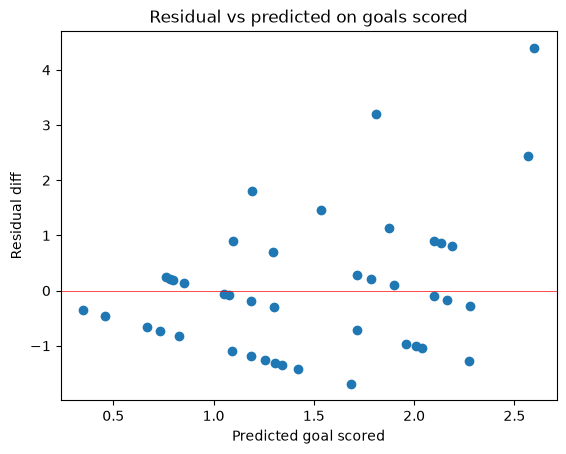

In [32]:
fig, axs = plt.subplots()
axs.scatter(pred2, y_test2-pred2)
axs.axhline(0, color="red", linewidth=0.5)
axs.set_xlabel("Predicted goal scored")
axs.set_ylabel("Residual diff")
axs.set_title("Residual vs predicted on goals scored")
plt.show()

## 5. Question 2

The goal is to predict how many goals a team scores in a match. Each match gives two rows, one for each team, so 104 matches, 208 rows total.

### The eight inputs

We write each input from the point of view of the team in that row, called the team, against the other side, called the opponent. A team's goals depend on its own attack and on the opponent's strength, so the team's Elo rating and the opponent's Elo rating are two separate inputs.

| # | Column name | What does it mean? | Why it might matter | Known before kick-off? |
|---|---|---|---|---|
| 1 | `team_elo` | The team's own Elo rating. | Stronger teams score more. | Yes, from before tourney as described before. |
| 2 | `opponent_elo` | The opponent's Elo rating. | A stronger opponent allows fewer goals. | Same as above |
| 3 | `venue_elevation_m` | The height of the stadium above sea level, in metres. | Thin air at high altitude can tire players. | Yes. The schedule shows the venue in advance. |
| 4 | `team_forwards` | The number of forwards in the team's squad. | More forwards can mean a more attacking team. | Yes. It comes from the squad list. |
| 5 | `travel_km` | Distance in kilometres from the venue of the team's previous match. A first match counts as 0. | Long trips can tire players. | Yes. The schedule shows both venues in advance. |
| 6 | `is_knockout` | 1 for a knockout match and 0 for a group match. | Knockout matches may be more cautious. | Yes. The schedule shows the stage in advance. |
| 7 | `team_is_host` | 1 if the team plays in its own country. | Home crowd and no travel. | Yes. The schedule shows the teams and venue in advance. |
| 8 | `venue_capacity` | The number of seats in the stadium. | A bigger crowd may add pressure and atmosphere. | Yes. The schedule shows the venue in advance. |

# How many goals does a team score?

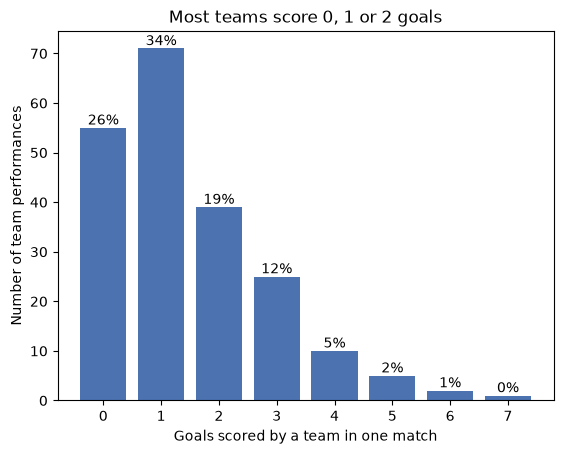

Observation:

- A team scored 1.48 goals per match on average. 26% of team performances had no goals, and 79% had 0 to 2 goals.
- The most any team scored was 7.


In [33]:
g = goals_pred_ds[TARGET_2]
counts = g.value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(counts.index, counts.values, color=BLUE)
for key, val in counts.items():
    ax.text(key, val, f"{val / len(g):.0%}", ha="center", va="bottom")
ax.set_xlabel("Goals scored by a team in one match")
ax.set_ylabel("Number of team performances")
ax.set_title("Most teams score 0, 1 or 2 goals")
ax.set_xticks(counts.index)
plt.show()

show(f"""Observation:

- A team scored {g.mean():.2f} goals per match on average. {(g == 0).mean():.0%} of team performances had no goals, and {(g <= 2).mean():.0%} had 0 to 2 goals.
- The most any team scored was {g.max()}.
""")

### 6.2 Do stronger teams score more?

We split the 208 team performances into four equal groups by the team's own Elo rating and compare the average goals scored in each group.

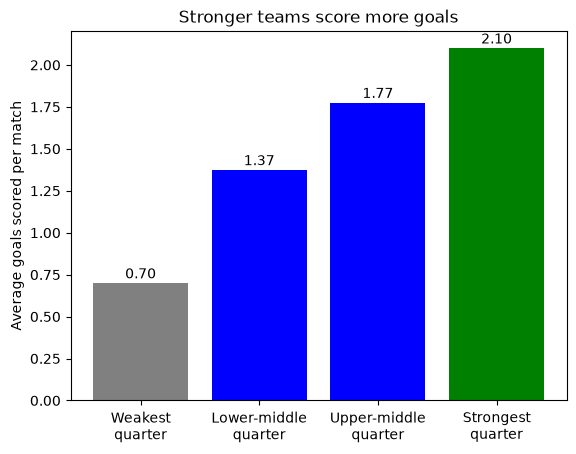

**What the numbers say.**

- The weakest quarter of teams scored 0.70 goals per match and the strongest quarter scored 2.10, which is 3.0 times as many.
- Host nations playing in their own country averaged 2.23 goals over 13 team performances, against 1.43 for everyone else.
- The first-listed team averaged 1.85 goals and the second-listed team 1.12. The fixture list tends to put the stronger side first, so this gap reflects strength and not the listing order.

In [34]:
goals_pred_ds["elo_group"] = pd.qcut(goals_pred_ds["team_elo"], 4, labels=["Weakest\nquarter", "Lower-middle\nquarter", "Upper-middle\nquarter", "Strongest\nquarter"])
by_elo = goals_pred_ds.groupby("elo_group", observed=True)[TARGET_2].agg(["mean", "size"])

fig, ax = plt.subplots()
ax.bar(by_elo.index.astype(str), by_elo["mean"], color=["grey", "blue", "blue", "green"])
for i, (m, s) in enumerate(zip(by_elo["mean"], by_elo["size"])):
    ax.text(i, m + 0.03, f"{m:.2f}", ha="center", fontsize=10)
ax.set_ylabel("Average goals scored per match")
ax.set_title("Stronger teams score more goals")
ax.grid(axis="x", alpha=0)
plt.show()

host_avg = goals_pred_ds.loc[goals_pred_ds.team_is_host == 1, TARGET_2].mean()
nonhost_avg = goals_pred_ds.loc[goals_pred_ds.team_is_host == 0, TARGET_2].mean()
first_avg = goals_pred_ds.groupby("match_id")[TARGET_2].first().mean()
second_avg = goals_pred_ds.groupby("match_id")[TARGET_2].last().mean()
show(f"""**What the numbers say.**

- The weakest quarter of teams scored {by_elo['mean'].iloc[0]:.2f} goals per match and the strongest quarter scored {by_elo['mean'].iloc[-1]:.2f}, which is {by_elo['mean'].iloc[-1] / by_elo['mean'].iloc[0]:.1f} times as many.
- Host nations playing in their own country averaged {host_avg:.2f} goals over {int((goals_pred_ds.team_is_host == 1).sum())} team performances, against {nonhost_avg:.2f} for everyone else.
- The first-listed team averaged {first_avg:.2f} goals and the second-listed team {second_avg:.2f}. The fixture list tends to put the stronger side first, so this gap reflects strength and not the listing order.""")

### 7.3 Predictions against reality

We sort the 208 team performances into five groups, from the group where the model expects the fewest goals to the group where it expects the most. Then we compare the average prediction with the average real result in each group. If the bars have similar heights, the predictions are well calibrated.

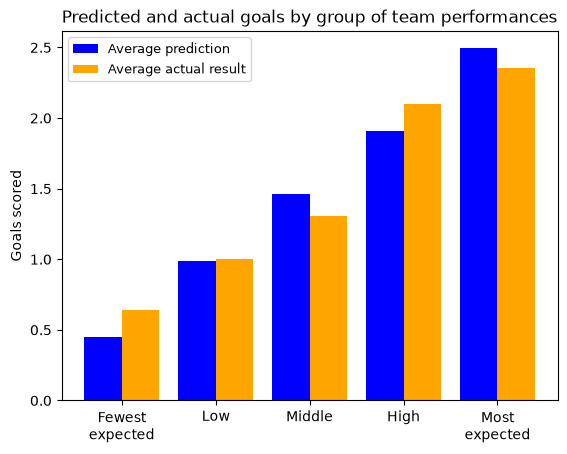

**What the numbers say.**

- The model ranks the groups in the right order. The group it expected to score least scored least, with 0.64 goals on average, and the group it expected to score most scored most, with 2.36.
- At the high end the model predicted 2.49 goals and the actual average was 2.36.
- At the low end the predictions are too low. The model predicted 0.45 goals for the lowest group, and that group scored 0.64. Straight-line models can predict below zero for counts, and 4 of the 208 predictions were below zero goals, which is impossible.
- Use the model to rank likely high scorers and low scorers. Do not use it to forecast an exact score.

In [35]:
X22, y22, grp_ids = goals_pred_ds[FEATURES_2].astype(float), goals_pred_ds[TARGET_2], goals_pred_ds["match_id"]

oof22 = oof_predict(MODEL, X22, y22, PERMA_SEED, groups=grp_ids)
cal = pd.DataFrame({"pred": oof22, "actual": y22.values})
cal["bin"] = pd.qcut(cal["pred"], 5, labels=["Fewest\nexpected", "Low", "Middle", "High", "Most\nexpected"])
cal_g = cal.groupby("bin", observed=True).agg(pred=("pred", "mean"), actual=("actual", "mean"), n=("pred", "size"))

x = np.arange(len(cal_g))
fig, ax = plt.subplots()
ax.bar(x - 0.2, cal_g["pred"], 0.4, color="blue", label="Average prediction")
ax.bar(x + 0.2, cal_g["actual"], 0.4, color="orange", label="Average actual result")
ax.set_xticks(x)
ax.set_xticklabels(cal_g.index.astype(str))
ax.set_ylabel("Goals scored")
ax.set_title("Predicted and actual goals by group of team performances")
ax.legend(fontsize=9)
ax.grid(axis="x", alpha=0)
plt.show()

n_neg = int((oof22 < 0).sum())
show(f"""**What the numbers say.**

- The model ranks the groups in the right order. The group it expected to score least scored least, with {cal_g['actual'].iloc[0]:.2f} goals on average, and the group it expected to score most scored most, with {cal_g['actual'].iloc[-1]:.2f}.
- At the high end the model predicted {cal_g['pred'].iloc[-1]:.2f} goals and the actual average was {cal_g['actual'].iloc[-1]:.2f}.
- At the low end the predictions are too low. The model predicted {cal_g['pred'].iloc[0]:.2f} goals for the lowest group, and that group scored {cal_g['actual'].iloc[0]:.2f}. Straight-line models can predict below zero for counts, and {n_neg} of the 208 predictions were below zero goals, which is impossible.
- Use the model to rank likely high scorers and low scorers. Do not use it to forecast an exact score.""")